<center><h1>Liang_Jean_HW6</h1></center>

Name: 
<br>
Github Username: 
<br>
USC ID: 

## 1. Tree-Based Methods

Import packages

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, roc_curve, roc_auc_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
from sklearn.preprocessing import StandardScaler

### (a) Download the APS Failure data

In [7]:
with zipfile.ZipFile("Homework 6 Data.zip") as data_zip:
    train_df = pd.read_csv(
        data_zip.open("aps_failure_training_set.csv"),
        skiprows=20,
        na_values="na"
    )
    test_df = pd.read_csv(
        data_zip.open("aps_failure_test_set.csv"),
        skiprows=20,
        na_values="na"
    )

print("Training data:", train_df.shape)
print("Test data:", test_df.shape)
train_df.head()

Training data: (60000, 171)
Test data: (16000, 171)


,class,aa_000,ab_000,ac_000,ad_000,ae_000,af_000,ag_000,ag_001,ag_002,...,ee_002,ee_003,ee_004,ee_005,ee_006,ee_007,ee_008,ee_009,ef_000,eg_000
0,neg,76698,NaN,2.130706e+09,280.0,0.0,0.0,0.0,0.0,0.0,...,1240520.0,493384.0,721044.0,469792.0,339156.0,157956.0,73224.0,0.0,0.0,0.0
1,neg,33058,NaN,0.000000e+00,NaN,0.0,0.0,0.0,0.0,0.0,...,421400.0,178064.0,293306.0,245416.0,133654.0,81140.0,97576.0,1500.0,0.0,0.0
2,neg,41040,NaN,2.280000e+02,100.0,0.0,0.0,0.0,0.0,0.0,...,277378.0,159812.0,423992.0,409564.0,320746.0,158022.0,95128.0,514.0,0.0,0.0
3,neg,12,0.0,7.000000e+01,66.0,0.0,10.0,0.0,0.0,0.0,...,240.0,46.0,58.0,44.0,10.0,0.0,0.0,0.0,4.0,32.0
4,neg,60874,NaN,1.368000e+03,458.0,0.0,0.0,0.0,0.0,0.0,...,622012.0,229790.0,405298.0,347188.0,286954.0,311560.0,433954.0,1218.0,0.0,0.0


### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Common techniques for handling missing data include deleting rows or columns, replacing missing values with a mean, median, mode, or constant, and using methods such as k-nearest neighbors or iterative imputation. I will use median imputation for the numeric features. The median is less affected by extreme values than the mean, which makes it a reasonable simple method for this data. The class label will not be imputed.

#### (ii) Calculate the coefficient of variation

In [12]:
X_train = train_df.drop(columns="class")

imputer = SimpleImputer(strategy="median")
X_train_imputed = pd.DataFrame(
    imputer.fit_transform(X_train),
    columns=X_train.columns,
    index=X_train.index
)

cv = (
    X_train_imputed.std(ddof=1) / X_train_imputed.mean()
).rename("CV").sort_values(ascending=False)

with pd.option_context("display.max_rows", None):
    display(cv.to_frame())

# print("Number of features:", len(cv))

,CV
cf_000,244.887517
co_000,244.507385
ad_000,244.322816
cs_009,237.930554
dh_000,123.216097
dj_000,117.494225
ag_000,92.917755
as_000,87.332500
ay_009,84.733735
ak_000,80.424975


#### (iii) Plot a correlation matrix

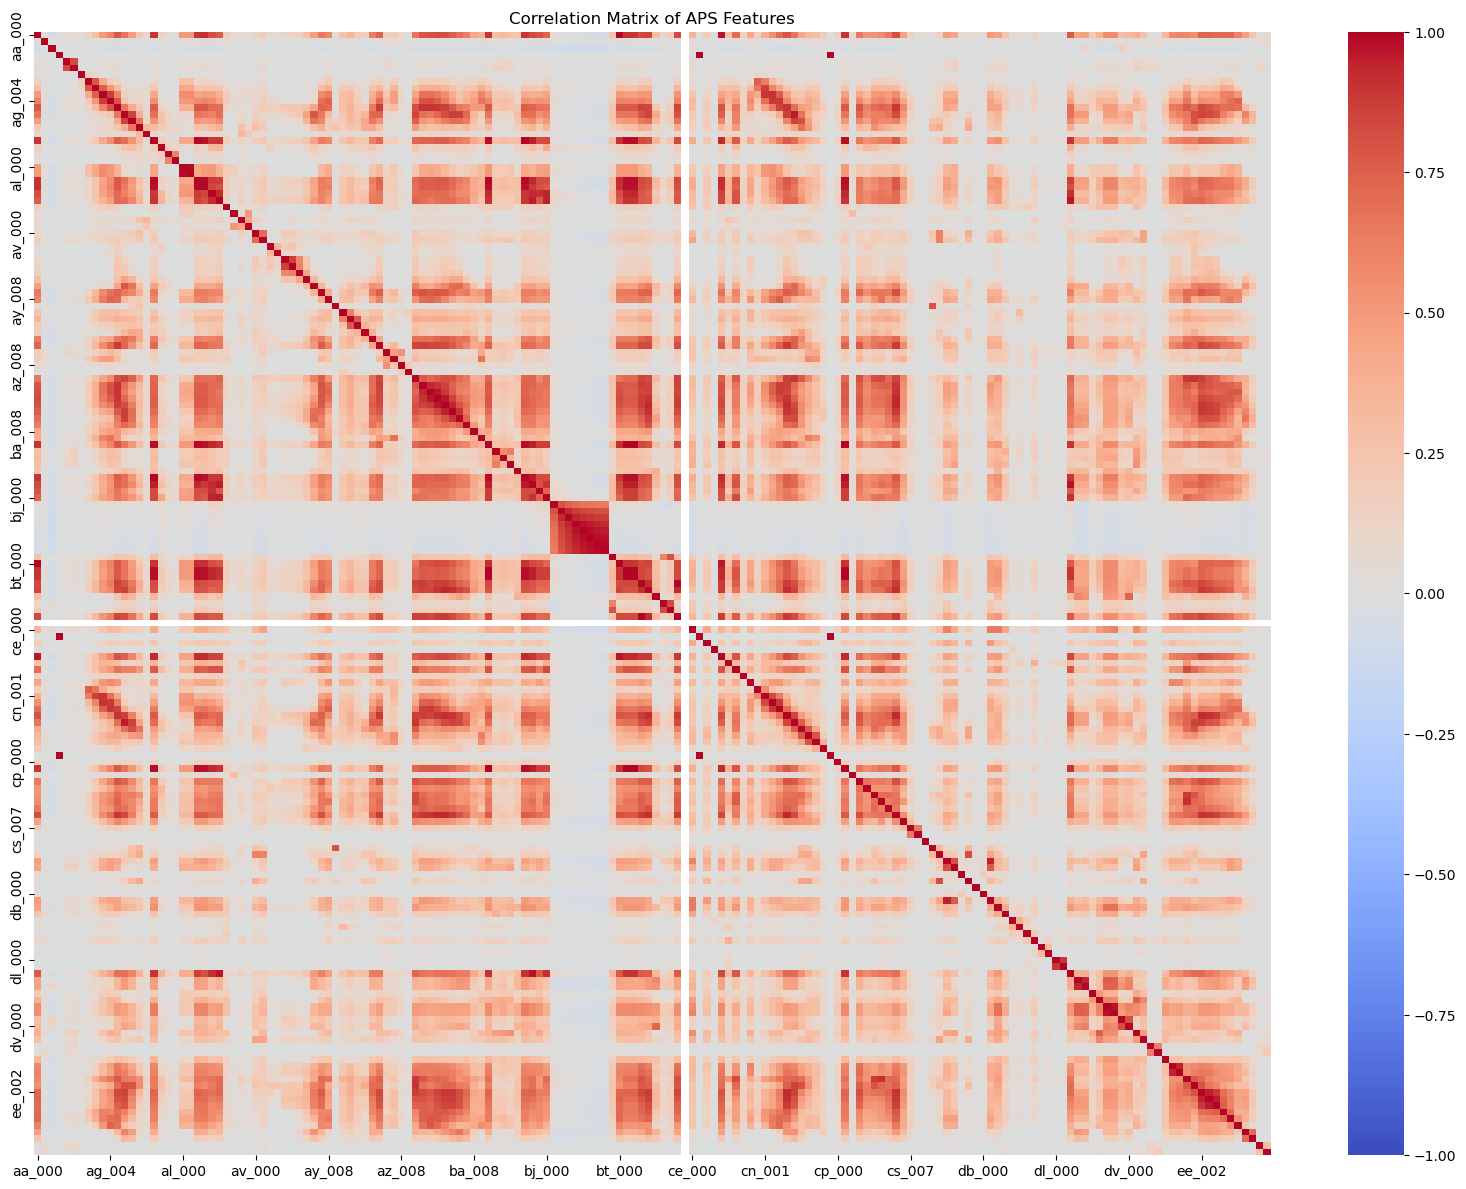

In [14]:
corr_matrix = X_train_imputed.corr()

plt.figure(figsize=(16, 12))
sns.heatmap(
    corr_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    xticklabels=10,
    yticklabels=10
)
plt.title("Correlation Matrix of APS Features")
plt.tight_layout()
plt.show()

#### (iv) Make scatter plots and box plots

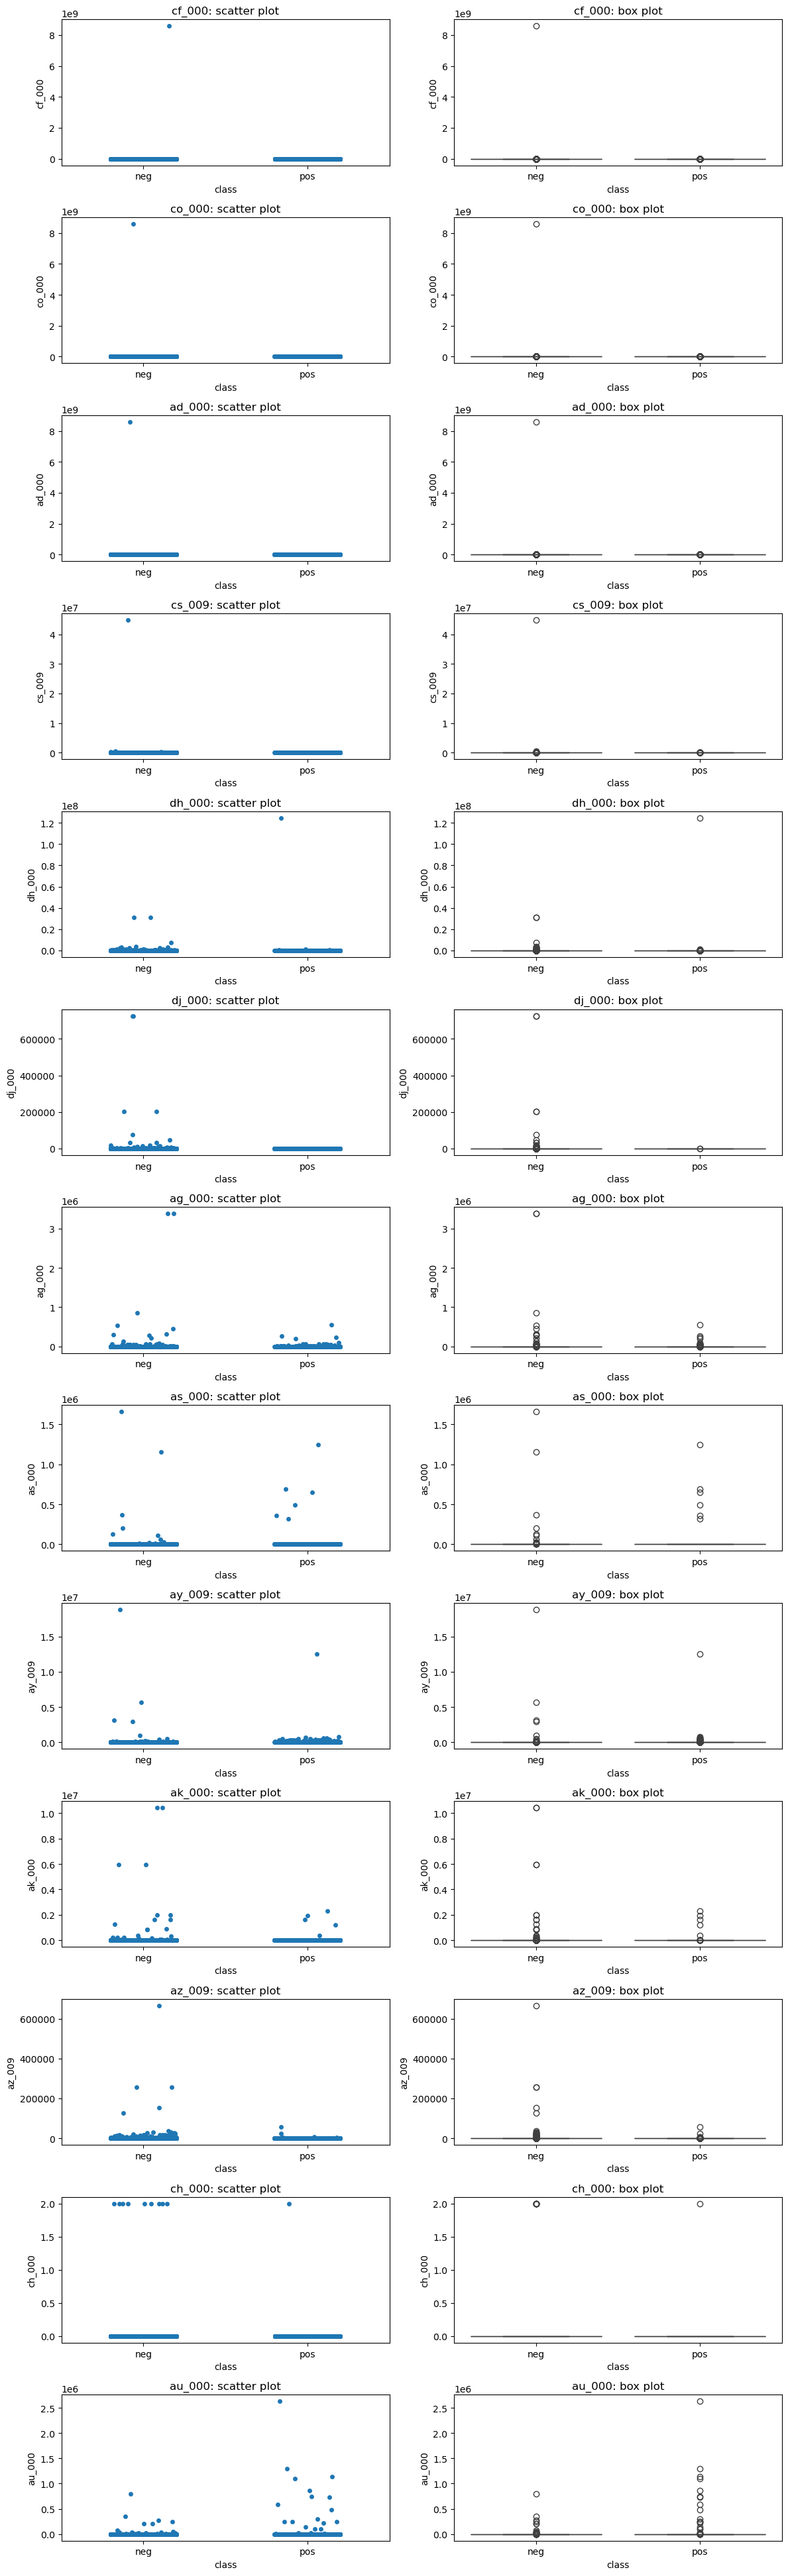

In [16]:
top_features = cv.head(13).index.tolist()

plot_data = X_train_imputed[top_features].copy()
plot_data["class"] = train_df["class"]

fig, axes = plt.subplots(13, 2, figsize=(12, 39))

for i, feature in enumerate(top_features):
    sns.stripplot(
        data=plot_data, x="class", y=feature,
        jitter=0.2, ax=axes[i, 0]
    )
    axes[i, 0].set_title(f"{feature}: scatter plot")

    sns.boxplot(
        data=plot_data, x="class", y=feature,
        ax=axes[i, 1]
    )
    axes[i, 1].set_title(f"{feature}: box plot")

plt.tight_layout()
plt.show()

The plots show that several features are highly skewed and contain extreme values. Some features appear to have different distributions across the two classes, but these plots alone cannot determine whether the differences are statistically significant or whether the features are useful predictors. A formal statistical test or model evaluation would be needed.

#### (v) Is this data set imbalanced?

In [19]:
train_df["class"].value_counts()

class
neg    59000
pos     1000
Name: count, dtype: int64

The training set contains 59,000 negative cases and 1,000 positive cases. The data is highly imbalanced, with 59 negative cases for every positive case.

### (c) Train a random forest

Training confusion matrix:
[[59000     0]
 [    0  1000]]
Training misclassification rate: 0.0
Training AUC: 1.0

Test confusion matrix:
[[15610    15]
 [  107   268]]
Test misclassification rate: 0.007624999999999993
Test AUC: 0.9943505920000001

OOB error: 0.006216666666666648


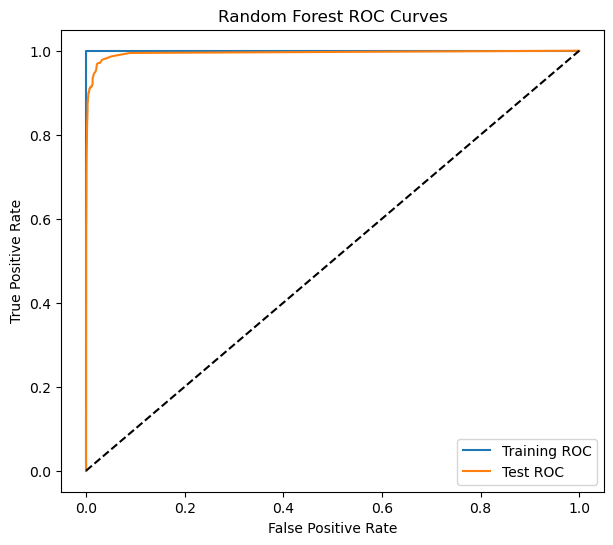

In [22]:
X_test = test_df.drop(columns="class")
X_test_imputed = pd.DataFrame(
    imputer.transform(X_test),
    columns=X_test.columns,
    index=X_test.index
)

y_train = train_df["class"].eq("pos").astype(int)
y_test = test_df["class"].eq("pos").astype(int)

rf = RandomForestClassifier(
    oob_score=True,
    random_state=1,
    n_jobs=-1
)
rf.fit(X_train_imputed, y_train)

train_pred = rf.predict(X_train_imputed)
test_pred = rf.predict(X_test_imputed)
train_prob = rf.predict_proba(X_train_imputed)[:, 1]
test_prob = rf.predict_proba(X_test_imputed)[:, 1]

print("Training confusion matrix:")
print(confusion_matrix(y_train, train_pred))
print("Training misclassification rate:", 1 - accuracy_score(y_train, train_pred))
print("Training AUC:", roc_auc_score(y_train, train_prob))

print("\nTest confusion matrix:")
print(confusion_matrix(y_test, test_pred))
print("Test misclassification rate:", 1 - accuracy_score(y_test, test_pred))
print("Test AUC:", roc_auc_score(y_test, test_prob))

print("\nOOB error:", 1 - rf.oob_score_)

train_fpr, train_tpr, _ = roc_curve(y_train, train_prob)
test_fpr, test_tpr, _ = roc_curve(y_test, test_prob)

plt.figure(figsize=(7, 6))
plt.plot(train_fpr, train_tpr, label="Training ROC")
plt.plot(test_fpr, test_tpr, label="Test ROC")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Random Forest ROC Curves")
plt.legend()
plt.show()

The random forest had a training misclassification rate of 0 and an AUC of 1.000. On the test set, the misclassification rate was 0.007625 and the AUC was 0.9944. The test confusion matrix had 15,610 true negatives, 15 false positives, 107 false negatives, and 268 true positives. The OOB error was 0.006217, which was close to the test misclassification rate.

### (d) Research class imbalance in random forest

Class imbalance in random forests can be handled with class weights or by resampling the training data. I use class_weight="balanced", which gives more weight to the less frequent class, so positive cases have more influence when the trees are built. scikit-learn 1.10.dev0 documentation

Training confusion matrix:
[[59000     0]
 [    0  1000]]
Training misclassification rate: 0.0
Training AUC: 1.0

Test confusion matrix:
[[15607    18]
 [  163   212]]
Test misclassification rate: 0.011312499999999948
Test AUC: 0.9894632106666669

OOB error: 0.0075666666666667215


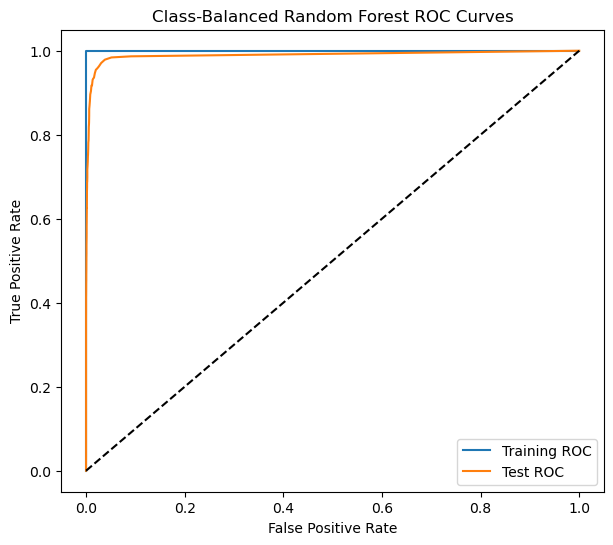

In [26]:
rf_balanced = RandomForestClassifier(
    class_weight="balanced",
    oob_score=True,
    random_state=1,
    n_jobs=-1
)
rf_balanced.fit(X_train_imputed, y_train)

train_pred_bal = rf_balanced.predict(X_train_imputed)
test_pred_bal = rf_balanced.predict(X_test_imputed)
train_prob_bal = rf_balanced.predict_proba(X_train_imputed)[:, 1]
test_prob_bal = rf_balanced.predict_proba(X_test_imputed)[:, 1]

print("Training confusion matrix:")
print(confusion_matrix(y_train, train_pred_bal))
print("Training misclassification rate:", 1 - accuracy_score(y_train, train_pred_bal))
print("Training AUC:", roc_auc_score(y_train, train_prob_bal))

print("\nTest confusion matrix:")
print(confusion_matrix(y_test, test_pred_bal))
print("Test misclassification rate:", 1 - accuracy_score(y_test, test_pred_bal))
print("Test AUC:", roc_auc_score(y_test, test_prob_bal))

print("\nOOB error:", 1 - rf_balanced.oob_score_)

train_fpr_bal, train_tpr_bal, _ = roc_curve(y_train, train_prob_bal)
test_fpr_bal, test_tpr_bal, _ = roc_curve(y_test, test_prob_bal)

plt.figure(figsize=(7, 6))
plt.plot(train_fpr_bal, train_tpr_bal, label="Training ROC")
plt.plot(test_fpr_bal, test_tpr_bal, label="Test ROC")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Class-Balanced Random Forest ROC Curves")
plt.legend()
plt.show()

In this run, using class_weight="balanced" did not improve test performance. The test misclassification rate increased from 0.007625 to 0.011313, and the test AUC decreased from 0.9944 to 0.9895. The balanced model also missed more positive cases (163 versus 107). Its OOB error was 0.007567, compared with 0.006217 for the uncompensated model. The training results were perfect for both models.

### (e) XGBoost and Model Trees

Best alpha: 0.01
5-fold CV misclassification rate: 0.006399999999999961

Training confusion matrix:
[[59000     0]
 [    1   999]]
Training misclassification rate: 1.666666666666483e-05
Training AUC: 0.9999999491525424

Test confusion matrix:
[[15609    16]
 [   85   290]]
Test misclassification rate: 0.006312500000000054
Test AUC: 0.993502208


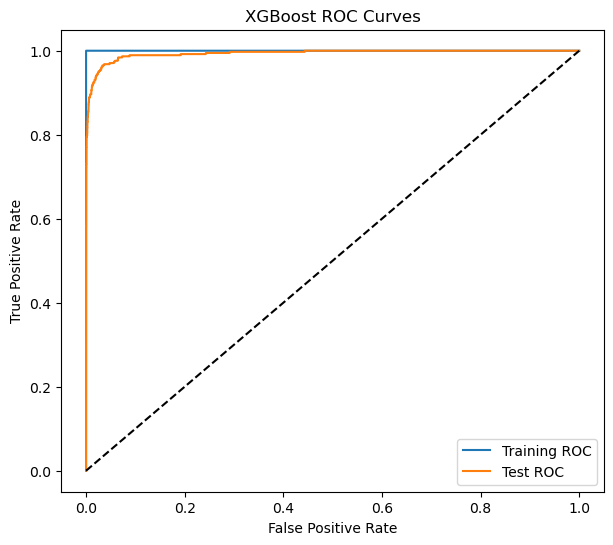

In [29]:
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=1,
        n_jobs=-1
    ))
])

param_grid = {
    "model__reg_alpha": [0, 0.01, 0.1, 1, 10]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

grid = GridSearchCV(
    xgb_pipeline,
    param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=1
)
grid.fit(X_train, y_train)

best_xgb = grid.best_estimator_

print("Best alpha:", grid.best_params_["model__reg_alpha"])
print("5-fold CV misclassification rate:", 1 - grid.best_score_)

train_pred_xgb = best_xgb.predict(X_train)
test_pred_xgb = best_xgb.predict(X_test)
train_prob_xgb = best_xgb.predict_proba(X_train)[:, 1]
test_prob_xgb = best_xgb.predict_proba(X_test)[:, 1]

print("\nTraining confusion matrix:")
print(confusion_matrix(y_train, train_pred_xgb))
print("Training misclassification rate:", 1 - accuracy_score(y_train, train_pred_xgb))
print("Training AUC:", roc_auc_score(y_train, train_prob_xgb))

print("\nTest confusion matrix:")
print(confusion_matrix(y_test, test_pred_xgb))
print("Test misclassification rate:", 1 - accuracy_score(y_test, test_pred_xgb))
print("Test AUC:", roc_auc_score(y_test, test_prob_xgb))

train_fpr_xgb, train_tpr_xgb, _ = roc_curve(y_train, train_prob_xgb)
test_fpr_xgb, test_tpr_xgb, _ = roc_curve(y_test, test_prob_xgb)

plt.figure(figsize=(7, 6))
plt.plot(train_fpr_xgb, train_tpr_xgb, label="Training ROC")
plt.plot(test_fpr_xgb, test_tpr_xgb, label="Test ROC")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost ROC Curves")
plt.legend()
plt.show()

The selected alpha was 0.01. The 5-fold cross-validation misclassification rate was 0.0064, close to the test misclassification rate of 0.0063125. The test AUC was 0.9935. The test confusion matrix had 15,609 true negatives, 16 false positives, 85 false negatives, and 290 true positives.

### (f) Use SMOTE to pre-process your data

Best alpha: 1
5-fold CV misclassification rate: 0.006616666666666604

Training confusion matrix:
[[59000     0]
 [    3   997]]
Training misclassification rate: 4.999999999999449e-05
Training AUC: 0.9999839152542372

Test confusion matrix:
[[15580    45]
 [   63   312]]
Test misclassification rate: 0.006750000000000034
Test AUC: 0.9937660586666667


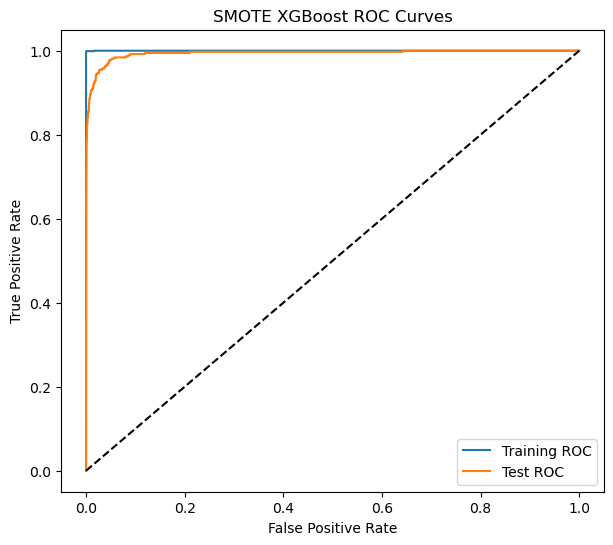

In [32]:
smote_pipeline = ImbPipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("smote", SMOTE(random_state=1)),
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        tree_method="hist",
        random_state=1,
        n_jobs=-1
    ))
])

smote_grid = GridSearchCV(
    smote_pipeline,
    {"model__reg_alpha": [0, 0.01, 0.1, 1, 10]},
    scoring="accuracy",
    cv=cv,
    n_jobs=1
)
smote_grid.fit(X_train, y_train)

best_xgb_smote = smote_grid.best_estimator_

print("Best alpha:", smote_grid.best_params_["model__reg_alpha"])
print("5-fold CV misclassification rate:", 1 - smote_grid.best_score_)

train_pred_smote = best_xgb_smote.predict(X_train)
test_pred_smote = best_xgb_smote.predict(X_test)
train_prob_smote = best_xgb_smote.predict_proba(X_train)[:, 1]
test_prob_smote = best_xgb_smote.predict_proba(X_test)[:, 1]

print("\nTraining confusion matrix:")
print(confusion_matrix(y_train, train_pred_smote))
print("Training misclassification rate:", 1 - accuracy_score(y_train, train_pred_smote))
print("Training AUC:", roc_auc_score(y_train, train_prob_smote))

print("\nTest confusion matrix:")
print(confusion_matrix(y_test, test_pred_smote))
print("Test misclassification rate:", 1 - accuracy_score(y_test, test_pred_smote))
print("Test AUC:", roc_auc_score(y_test, test_prob_smote))

train_fpr_smote, train_tpr_smote, _ = roc_curve(y_train, train_prob_smote)
test_fpr_smote, test_tpr_smote, _ = roc_curve(y_test, test_prob_smote)

plt.figure(figsize=(7, 6))
plt.plot(train_fpr_smote, train_tpr_smote, label="Training ROC")
plt.plot(test_fpr_smote, test_tpr_smote, label="Test ROC")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("SMOTE XGBoost ROC Curves")
plt.legend()
plt.show()

Compared with the uncompensated XGBoost model, SMOTE reduced the number of missed positive cases from 85 to 63, but increased false positives from 16 to 45. The test misclassification rate increased slightly from 0.006313 to 0.006750, while the test AUC increased slightly from 0.993502 to 0.993766. Thus, SMOTE detected more positive cases at the cost of more false alarms.

## 2. ISLR 6.6.3

(a) iv. Steadily decrease. As \(s\) increases, the constraint relaxes, so the model can fit the training data at least as well as before.

(b) ii. Decrease initially, then increase in a U shape. Increasing flexibility can first improve test fit, but too much flexibility can lead to overfitting.

(c) iii. Steadily increase. A more flexible model is more sensitive to changes in the training data.

(d) iv. Steadily decrease. Increasing flexibility lets the model represent the underlying relationship more closely.

(e) v. Remain constant. Irreducible error comes from inherent noise in the data and is unaffected by model flexibility.

## 3. ISLR 6.6.5

Let x be the shared value of the two predictors in the first observation, and let y be the response for that observation. The assumptions imply that the second observation has predictor values −x and response −y.

(a) Ridge regression minimizes the training RSS plus lambda times the sum of the squared coefficients. In this setting, the RSS is twice the squared difference between y and x times the sum of beta 1 and beta 2.

(b) For a fixed sum of beta 1 and beta 2, the ridge penalty is smallest when the two coefficients are equal. Therefore, the ridge estimates satisfy beta 1 equals beta 2.

(c) The lasso minimizes the same training RSS plus lambda times the sum of the absolute values of beta 1 and beta 2.

(d) For a fixed, nonzero sum of the two coefficients, the lasso penalty is smallest whenever both coefficients have the same sign. Any such pair with that sum gives the same objective, so there are multiple lasso solutions. For a positive sum, both coefficients can be nonnegative; for a negative sum, both can be nonpositive.

## 4. ISLR 8.4.5

Using majority vote, the final classification is Red because 6 of the 10 trees classify the observation as Red. Using the average probability, the mean probability of Red is 0.45, which is below 0.5, so the final classification is Green.

## 5. ISLR 9.7.3

(a) Plot the four Red observations at (3, 4), (2, 2), (4, 4), and (1, 4). Plot the three Blue observations at (2, 1), (4, 3), and (4, 1).

(b) The optimal separating hyperplane is x2 = x1 - 0.5, or equivalently 1 - 2x1 + 2x2 = 0.

(c) Classify an observation as Red if 1 - 2x1 + 2x2 > 0, and as Blue otherwise. Thus, beta 0 = 1, beta 1 = -2, and beta 2 = 2.

(d) Draw the margin boundaries x2 = x1 and x2 = x1 - 1, with the optimal hyperplane halfway between them.

(e) The support vectors are observations 2 and 3 from the Red class, at (2, 2) and (4, 4), and observations 5 and 6 from the Blue class, at (2, 1) and (4, 3).

(f) Observation 7, at (4, 1), is not a support vector. A slight movement of it will not affect the optimal hyperplane as long as it stays away from the margin.

(g) One non-optimal separating hyperplane is x2 = x1 - 0.2. It still separates all the observations, but it is not halfway between the closest Red and Blue points.

(h) Add a Blue observation at (3, 3). This point lies on the line segment between the Red observations at (2, 2) and (4, 4), so the classes can no longer be separated by a hyperplane.